# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

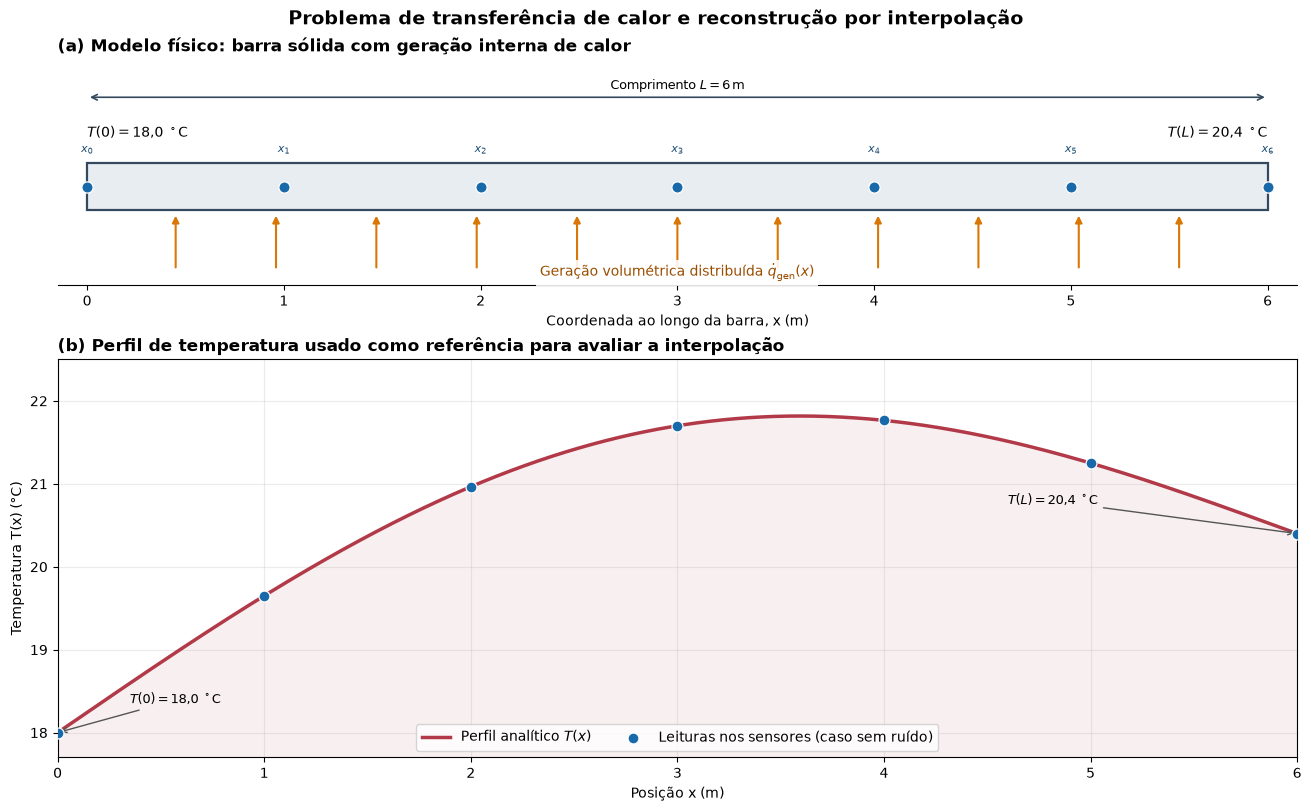

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


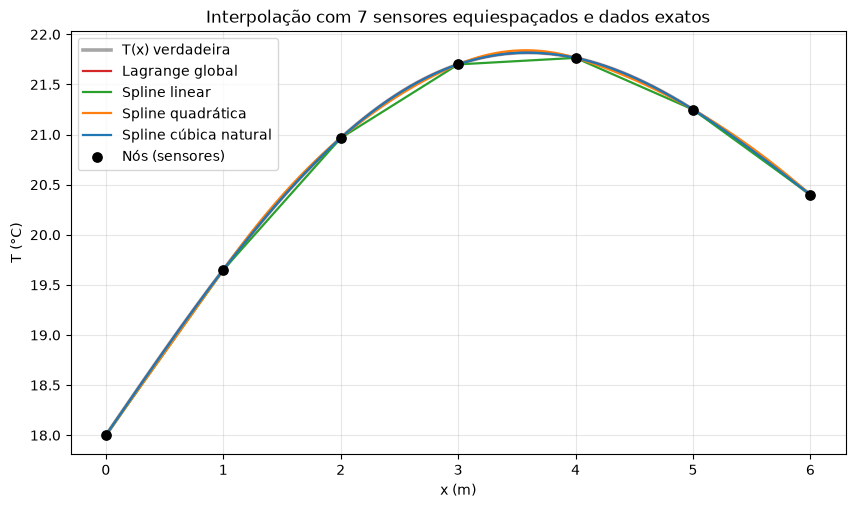

In [4]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Métricas na malha fina (pontos entre os nós)
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# Curvas dos quatro métodos sobre a função verdadeira
cores = {"Lagrange global":"#d62728", "Spline linear":"#2ca02c",
         "Spline quadrática":"#ff7f0e", "Spline cúbica natural":"#1f77b4"}
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x_fino, T_fino, "k", lw=2.6, alpha=0.35, label="T(x) verdadeira")
for nome, m in metodos_7.items():
    ax.plot(x_fino, m(x_fino), lw=1.6, color=cores[nome], label=nome)
ax.scatter(x_nos_7, y_nos_7, c="k", zorder=5, s=45, label="Nós (sensores)")
ax.set_xlabel("x (m)"); ax.set_ylabel("T (°C)")
ax.set_title("Interpolação com 7 sensores equiespaçados e dados exatos")
ax.grid(alpha=0.3); ax.legend(); plt.show()

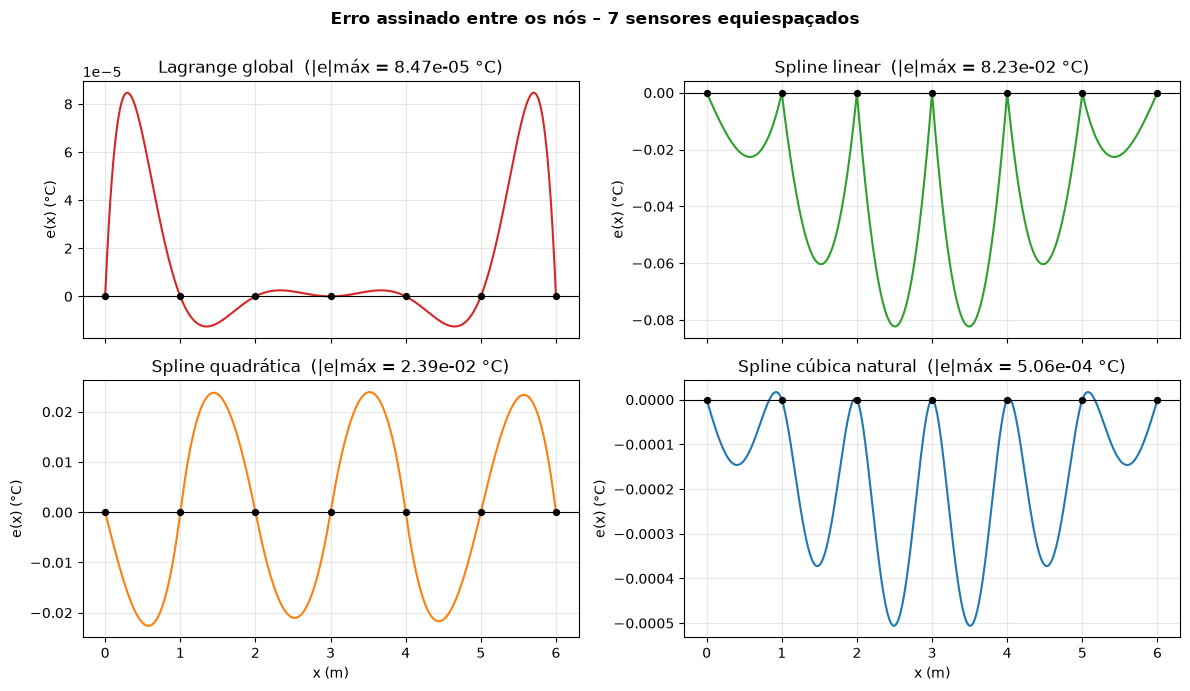

In [5]:
# Erros assinados e(x) = p(x) - T(x), método a método
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (nome, m) in zip(axs.ravel(), metodos_7.items()):
    erro = m(x_fino) - T_fino
    ax.plot(x_fino, erro, color=cores[nome], lw=1.5)
    ax.axhline(0, color="k", lw=0.8)
    ax.scatter(x_nos_7, np.zeros_like(x_nos_7), c="k", s=18, zorder=5)
    ax.set_title(f"{nome}  (|e|máx = {np.max(np.abs(erro)):.2e} °C)")
    ax.set_ylabel("e(x) (°C)"); ax.grid(alpha=0.3)
for ax in axs[1]: ax.set_xlabel("x (m)")
fig.suptitle("Erro assinado entre os nós – 7 sensores equiespaçados", weight="bold")
fig.tight_layout(); plt.show()

### Análise da Etapa 1

| Método | Erro máx. (°C) | MAE (°C) | RMSE (°C) |
|---|---|---|---|
| Lagrange global | 8,5·10⁻⁵ | 1,9·10⁻⁵ | 3,3·10⁻⁵ |
| Spline cúbica natural | 5,1·10⁻⁴ | 1,8·10⁻⁴ | 2,4·10⁻⁴ |
| Spline quadrática | 2,4·10⁻² | 1,5·10⁻² | 1,6·10⁻² |
| Spline linear | 8,2·10⁻² | 3,7·10⁻² | 4,4·10⁻² |

A precisão cresce com o grau da spline. O Lagrange é o melhor porque $T(x)$ é analítico e 7 nós já bastam. A spline cúbica natural também vai bem, pois $T''(0)=T''(L)=0$ coincide com a condição natural.

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [6]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

def erros_lagrange(x_nos):
    p = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
    e = p(x_fino) - T_fino
    return np.max(np.abs(e)), np.sqrt(np.mean(e**2))

linhas = []
for N in (5, 9, 13, 17):
    for dist, nos in (("Equiespaçados", np.linspace(x_min, x_max, N)),
                      ("Chebyshev-Lobatto", nos_chebyshev_lobatto(x_min, x_max, N))):
        emax, rmse = erros_lagrange(nos)
        linhas.append({"N": N, "Distribuição": dist, "Erro máximo (°C)": emax, "RMSE (°C)": rmse})
tabela_nos = pd.DataFrame(linhas)
display(tabela_nos.style.format({"Erro máximo (°C)":"{:.3e}", "RMSE (°C)":"{:.3e}"}))


,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçados,4.530e-03,2.160e-03
1,5,Chebyshev-Lobatto,2.327e-03,1.533e-03
2,9,Equiespaçados,1.044e-06,3.438e-07
3,9,Chebyshev-Lobatto,2.168e-07,1.202e-07
4,13,Equiespaçados,5.913e-11,1.546e-11
5,13,Chebyshev-Lobatto,3.624e-12,1.932e-12
6,17,Equiespaçados,1.990e-12,2.445e-13
7,17,Chebyshev-Lobatto,1.066e-14,3.743e-15


### Análise da Etapa 2

Chebyshev reduz o erro em todos os $N$ (de ~2× em $N=5$ até ~190× em $N=17$, quando o erro máximo cai de $2\cdot10^{-12}$ para $1\cdot10^{-14}$ °C), porque evita o crescimento do erro nas bordas (fenômeno de Runge). Como o perfil é muito suave, isso não prova o mesmo ganho para funções menos regulares.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

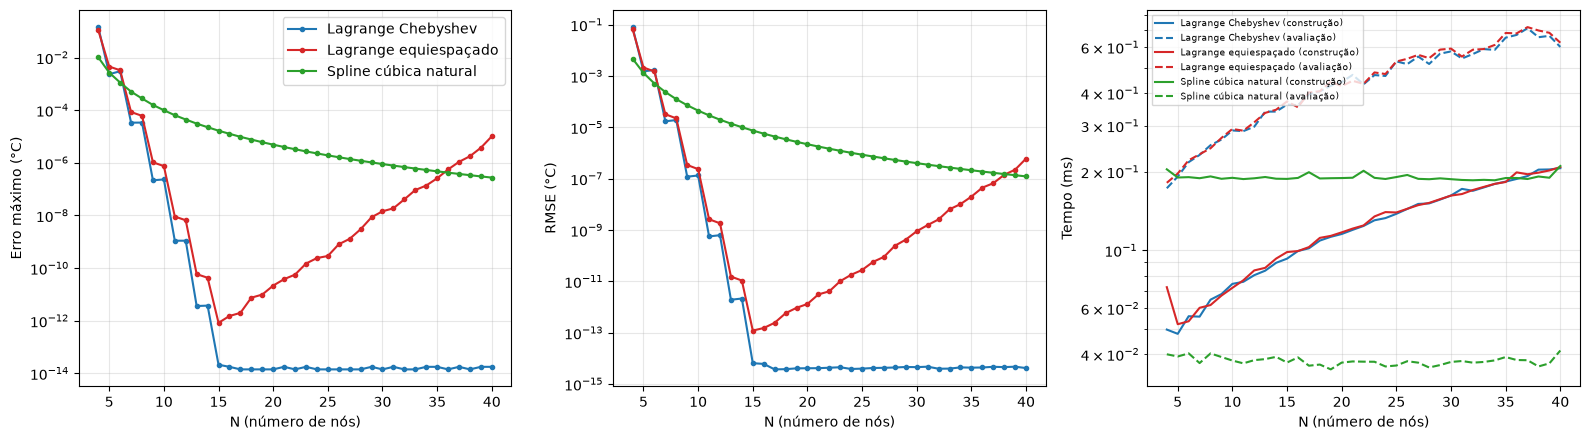

,t_construção (ms),t_avaliação (ms)
Método,,
Lagrange Chebyshev,0.126,0.449
Lagrange equiespaçado,0.128,0.457
Spline cúbica natural,0.190,0.038


               Método  N         Emax
   Lagrange Chebyshev 17 1.421085e-14
Lagrange equiespaçado 15 8.348877e-13
Spline cúbica natural 40 2.745707e-07


In [7]:
import time
Ns = np.arange(4, 41)
reg = []
for N in Ns:
    casos = {"Lagrange equiespaçado": np.linspace(x_min, x_max, N),
             "Lagrange Chebyshev": nos_chebyshev_lobatto(x_min, x_max, N),
             "Spline cúbica natural": np.linspace(x_min, x_max, N)}
    for nome, nos in casos.items():
        y = temperatura_real(nos)
        t0 = time.perf_counter()
        for _ in range(20):
            f = CubicSpline(nos, y, bc_type="natural") if nome.startswith("Spline") else BarycentricInterpolator(nos, y)
        t_cons = (time.perf_counter()-t0)/20
        t0 = time.perf_counter()
        for _ in range(20): v = f(x_fino)
        t_aval = (time.perf_counter()-t0)/20
        e = v - T_fino
        reg.append({"N": N, "Método": nome, "Emax": np.max(np.abs(e)),
                    "RMSE": np.sqrt(np.mean(e**2)), "t_construção (ms)": 1e3*t_cons, "t_avaliação (ms)": 1e3*t_aval})
estudo = pd.DataFrame(reg)

cores3 = {"Lagrange equiespaçado":"#d62728", "Lagrange Chebyshev":"#1f77b4", "Spline cúbica natural":"#2ca02c"}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for nome, g in estudo.groupby("Método"):
    axs[0].semilogy(g["N"], g["Emax"], "o-", ms=3, color=cores3[nome], label=nome)
    axs[1].semilogy(g["N"], g["RMSE"], "o-", ms=3, color=cores3[nome], label=nome)
    axs[2].semilogy(g["N"], g["t_construção (ms)"], "-", color=cores3[nome], label=nome+" (construção)")
    axs[2].semilogy(g["N"], g["t_avaliação (ms)"], "--", color=cores3[nome], label=nome+" (avaliação)")
for ax, t in zip(axs, ["Erro máximo (°C)", "RMSE (°C)", "Tempo (ms)"]):
    ax.set_xlabel("N (número de nós)"); ax.set_ylabel(t); ax.grid(alpha=0.3, which="both")
axs[0].legend(); axs[2].legend(fontsize=6.5)
plt.tight_layout(); plt.show()

sel = estudo[estudo["N"].isin([4, 8, 12, 16, 20, 30, 40])].pivot(index="N", columns="Método", values=["Emax", "RMSE"])
display(sel.style.format("{:.2e}"))
display(estudo.groupby("Método")[["t_construção (ms)", "t_avaliação (ms)"]].mean().style.format("{:.3f}"))
print(estudo.loc[estudo.groupby("Método")["Emax"].idxmin(), ["Método", "N", "Emax"]].to_string(index=False))

### Análise da Etapa 3

- **Chebyshev:** o erro cai até ~$10^{-14}$ °C em $N\approx16$ e fica estável.
- **Equiespaçado:** melhora até $N\approx15$ e depois piora ($7{,}6\cdot10^{-6}$ °C em $N=40$), por amplificação de erros de arredondamento (instabilidade numérica).
- **Spline cúbica:** converge de forma regular ($E_{max}\propto h^4$) e nunca degrada.
- **Custo:** construção ~0,1–0,2 ms em todos; avaliação ~0,41 ms (Lagrange) contra ~0,04 ms (spline). Desprezível aqui.

**Não há método único melhor:** com $N=4$ a spline vence ($0{,}01$ contra $\sim0{,}1$ °C); para $N\gtrsim8$, Lagrange com Chebyshev é o melhor; o equiespaçado só serve para $N$ moderado.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

## Recomendação técnica

Baseada nos resultados das Etapas 1 a 3 (Emax e RMSE).

- **Poucos sensores exatos (4–6):** spline cúbica. Com $N=4$ o erro máximo é ≈0,01 °C contra ≈0,1 °C no Lagrange, e não oscila.
- **Mais sensores:** Lagrange com nós de Chebyshev, se a posição puder ser escolhida (erro até ~$10^{-14}$ °C). Com grade uniforme, limitar o Lagrange a $N\approx12$–15 ou usar spline cúbica, que continua estável.
- **Com ruído:** não testado aqui. Como o Lagrange equiespaçado amplifica erros de arredondamento para $N$ grande (Etapa 3), é esperado que amplifique também o ruído; nesse caso, preferir spline cúbica ou Chebyshev com $N$ moderado e validar com dados reais.
- **Extremidades:** manter sensores nas pontas e, se possível, adensar nós perto delas (Chebyshev), conferindo o erro ali separadamente.
- **Interpolar × extrapolar:** as conclusões valem só dentro do intervalo medido; fora dele não há garantia de erro pequeno.
- **Limitações:** em campo $T$ é desconhecida, então Emax e RMSE não podem ser calculados; estimá-los por validação cruzada (retirar um sensor e prever). O perfil usado é suave e artificial.